<a href="https://colab.research.google.com/github/tagbofheyb11-web/Family_Income_and_Expenditure.csv/blob/main/Tagbo_Backpropagation_and_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

| Name | **TAGBO, Fheyb Shylbhe M.** |
|:---|:---|
| ID Number | 2025305242 |
| Section | CEA_CPE_2D_STEM |

# Coding Assignment 3: Backpropagation and Optimization

#1. Environment Setup and Data Exploration

In [9]:
#1.1 Package Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
import keras
from keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Times New Roman'
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print('Keras version:', keras.__version__)
print('TensorFlow version:', tf.__version__)

Keras version: 3.13.2
TensorFlow version: 2.21.0


In [11]:
#1.2 Load Data Sets

CSV_PATH = "https://raw.githubusercontent.com/tagbofheyb11-web/Family_Income_and_Expenditure.csv/refs/heads/main/Family_Income_and_Expenditure.csv"   # update path as needed
df = pd.read_csv(CSV_PATH)
print('Shape:', df.shape)
df.head()

Shape: (41544, 60)


,Total Household Income,Region,Total Food Expenditure,Main Source of Income,Agricultural Household indicator,Bread and Cereals Expenditure,Total Rice Expenditure,Meat Expenditure,Total Fish and marine products Expenditure,Fruit Expenditure,...,Number of Refrigerator/Freezer,Number of Washing Machine,Number of Airconditioner,"Number of Car, Jeep, Van",Number of Landline/wireless telephones,Number of Cellular phone,Number of Personal Computer,Number of Stove with Oven/Gas Range,Number of Motorized Banca,Number of Motorcycle/Tricycle
0,480332,CAR,117848,Wage/Salaries,0,42140,38300,24676,16806,3325,...,1,1,0,0,0,2,1,0,0,1
1,198235,CAR,67766,Wage/Salaries,0,17329,13008,17434,11073,2035,...,0,1,0,0,0,3,1,0,0,2
2,82785,CAR,61609,Wage/Salaries,1,34182,32001,7783,2590,1730,...,0,0,0,0,0,0,0,0,0,0
3,107589,CAR,78189,Wage/Salaries,0,34030,28659,10914,10812,690,...,0,0,0,0,0,1,0,0,0,0
4,189322,CAR,94625,Wage/Salaries,0,34820,30167,18391,11309,1395,...,1,0,0,0,0,3,0,0,0,1


In [12]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41544 entries, 0 to 41543
Data columns (total 60 columns):
 #   Column                                         Non-Null Count  Dtype 
---  ------                                         --------------  ----- 
 0   Total Household Income                         41544 non-null  int64 
 1   Region                                         41544 non-null  object
 2   Total Food Expenditure                         41544 non-null  int64 
 3   Main Source of Income                          41544 non-null  object
 4   Agricultural Household indicator               41544 non-null  int64 
 5   Bread and Cereals Expenditure                  41544 non-null  int64 
 6   Total Rice Expenditure                         41544 non-null  int64 
 7   Meat Expenditure                               41544 non-null  int64 
 8   Total Fish and  marine products Expenditure    41544 non-null  int64 
 9   Fruit Expenditure                              41544 non-null

,count,mean,std,min,25%,50%,75%,max
Total Household Income,41544.0,247555.584802,286880.522653,11285.0,104895.00,164079.5,291138.50,11815988.0
Total Food Expenditure,41544.0,85099.158194,51637.947682,2947.0,51017.25,72985.5,105635.50,827565.0
Agricultural Household indicator,41544.0,0.429858,0.676666,0.0,0.00,0.0,1.00,2.0
Bread and Cereals Expenditure,41544.0,25133.723642,13466.482984,0.0,16556.00,23324.0,31439.00,765864.0
Total Rice Expenditure,41544.0,18195.825005,11727.224350,0.0,11020.00,16620.0,23920.00,758326.0
Meat Expenditure,41544.0,10540.072574,10497.727757,0.0,3353.75,7332.5,14292.00,261566.0
Total Fish and marine products Expenditure,41544.0,10529.318337,7812.201613,0.0,5504.00,8695.0,13388.00,188208.0
Fruit Expenditure,41544.0,2550.474990,2969.752879,0.0,1024.75,1820.0,3100.00,273769.0
Vegetables Expenditure,41544.0,5006.918568,3300.175236,0.0,2873.00,4314.0,6304.25,74800.0
Restaurant and hotels Expenditure,41544.0,15436.566075,23705.195929,0.0,1930.00,7314.0,19921.25,725296.0


# 2. Data Preparation

In [13]:
# 2. Data Preparation

TARGET = 'Total Food Expenditure'

income_cols = [c for c in df.columns if c.strip().lower() in ('total income', 'total household income')]
print('Income column(s) found:', income_cols)
EXCLUDE = [TARGET] + income_cols

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in numeric_cols if c not in EXCLUDE]
X = df[feature_cols].fillna(df[feature_cols].median())
y = df[TARGET].fillna(df[TARGET].median())
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.2, random_state=42)

scaler_X = StandardScaler()
X_train_s = scaler_X.fit_transform(X_train)
X_test_s = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()

print('X_train_s:', X_train_s.shape)
print('X_test_s :', X_test_s.shape)

Income column(s) found: ['Total Household Income']
X_train_s: (33235, 43)
X_test_s : (8309, 43)


#3. Model Architecture

In [14]:
# 3. Model Architecture

def build_model(input_dim):
    model = models.Sequential([layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)])
    return model

input_dim = X_train_s.shape[1]
model = build_model(input_dim)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,929 (19.25 KB)

 Trainable params: 4,929 (19.25 KB)

 Non-trainable params: 0 (0.00 B)

# 4. Keras Optimizers

In [28]:
# 4. Keras Optimizers
from keras import optimizers as opt

def make_optimizers():
  OPTI = {
    'SGD':       lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
    'RMSprop':   lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    'Adam':      lambda: keras.optimizers.Adam(learning_rate=0.001),
    'AdamW':     lambda: keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004),
    'Adadelta':  lambda: keras.optimizers.Adadelta(learning_rate=0.001),
    'Adagrad':   lambda: keras.optimizers.Adagrad(learning_rate=0.001),
    'Adamax':    lambda: keras.optimizers.Adamax(learning_rate=0.001),
    'Adafactor': lambda: keras.optimizers.Adafactor(learning_rate=0.001),
    'Nadam':     lambda: keras.optimizers.Nadam(learning_rate=0.001),
    'Ftrl':      lambda: keras.optimizers.Ftrl(learning_rate=0.001),
    'Lion':      lambda: keras.optimizers.Lion(learning_rate=0.0001),
    'Lamb':      lambda: keras.optimizers.Lamb(learning_rate=0.001),
    'Muon':      lambda: keras.optimizers.Muon(learning_rate=0.001),
  }
  return OPTI

OPT_NAMES = list(make_optimizers().keys())
print(f'{len(OPT_NAMES)} optimizers registered:', OPT_NAMES)

13 optimizers registered: ['SGD', 'RMSprop', 'Adam', 'AdamW', 'Adadelta', 'Adagrad', 'Adamax', 'Adafactor', 'Nadam', 'Ftrl', 'Lion', 'Lamb', 'Muon']


# 5. Training Loop

In [29]:
# 5. Training Loop

EPOCHS = 80
BATCH  = 64
SEED   = 42
keras.utils.set_random_seed(SEED)

histories, metrics, trained_models, hist_orig = {}, {}, {}, {}
scale = scaler_y.scale_[0]
OPTI = make_optimizers()

for name, make_opt in OPTI.items():
    keras.utils.set_random_seed(SEED)
    model = build_model(X_train_s.shape[1])
    model.compile(optimizer=make_opt(), loss='mse')
    es = callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                 restore_best_weights=True)
    h = model.fit(X_train_s, y_train_s, validation_split=0.15,
                  epochs=EPOCHS, batch_size=BATCH, callbacks=[es], verbose=0)

    pred_s = model.predict(X_test_s, verbose=0)
    pred   = scaler_y.inverse_transform(pred_s).ravel()
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    r2   = float(r2_score(y_test, pred))

    n_ep     = len(h.history['loss'])
    tr_loss  = h.history['loss'][-1]     * scale**2
    val_loss = h.history['val_loss'][-1] * scale**2

    histories[name] = h.history
    hist_orig[name] = {'loss': np.array(h.history['loss']) * scale**2,
                       'val_loss': np.array(h.history['val_loss']) * scale**2}
    metrics[name] = dict(RMSE=rmse, R2=r2, TrainLoss=tr_loss, ValLoss=val_loss, Epochs=n_ep)
    trained_models[name] = model
    print(f'{name:10s} | RMSE = {rmse:12.2f} | R2 = {r2:7.4f} | epochs = {n_ep}')

SGD        | RMSE =     11064.50 | R2 =  0.9540 | epochs = 35
RMSprop    | RMSE =     11578.08 | R2 =  0.9496 | epochs = 23
Adam       | RMSE =     11284.77 | R2 =  0.9521 | epochs = 25
AdamW      | RMSE =     11271.94 | R2 =  0.9522 | epochs = 26
Adadelta   | RMSE =     27173.68 | R2 =  0.7223 | epochs = 80
Adagrad    | RMSE =     13143.86 | R2 =  0.9350 | epochs = 80
Adamax     | RMSE =     11239.65 | R2 =  0.9525 | epochs = 61
Adafactor  | RMSE =     11179.01 | R2 =  0.9530 | epochs = 80
Nadam      | RMSE =     11199.40 | R2 =  0.9528 | epochs = 26
Ftrl       | RMSE =     11167.18 | R2 =  0.9531 | epochs = 80
Lion       | RMSE =     11173.61 | R2 =  0.9530 | epochs = 25
Lamb       | RMSE =     11137.89 | R2 =  0.9533 | epochs = 29
Muon       | RMSE =     11332.97 | R2 =  0.9517 | epochs = 30


## 5.1 Record Your Results

In [30]:
# 5.1 Record Your Results

results = pd.DataFrame(metrics).T[['RMSE', 'R2', 'TrainLoss', 'ValLoss', 'Epochs']]
results.columns = ['RMSE', 'R2', 'Train Loss', 'Val Loss', 'Epochs']
results = results.loc[OPT_NAMES]                 # same row order as the sheet
results['Epochs'] = results['Epochs'].astype(int)
results.index.name = 'Optimizer'
results.reset_index().round(4)

,Optimizer,RMSE,R2,Train Loss,Val Loss,Epochs
0,SGD,11064.5014,0.9540,6.295762e+07,9.361937e+07,35
1,RMSprop,11578.0779,0.9496,6.290888e+07,1.065223e+08,23
2,Adam,11284.7731,0.9521,5.795412e+07,1.048570e+08,25
3,AdamW,11271.9372,0.9522,5.797624e+07,9.936286e+07,26
4,Adadelta,27173.6790,0.7223,6.770213e+08,6.935937e+08,80
5,Adagrad,13143.8618,0.9350,1.248037e+08,1.573951e+08,80
6,Adamax,11239.6491,0.9525,5.720699e+07,9.749555e+07,61
7,Adafactor,11179.0136,0.9530,6.018822e+07,9.831424e+07,80
8,Nadam,11199.3975,0.9528,5.745064e+07,9.805805e+07,26
9,Ftrl,11167.1794,0.9531,8.253104e+07,9.625000e+07,80


# 6. Visualizations

#6.1 Per-Optimizer Diagnostic Plots

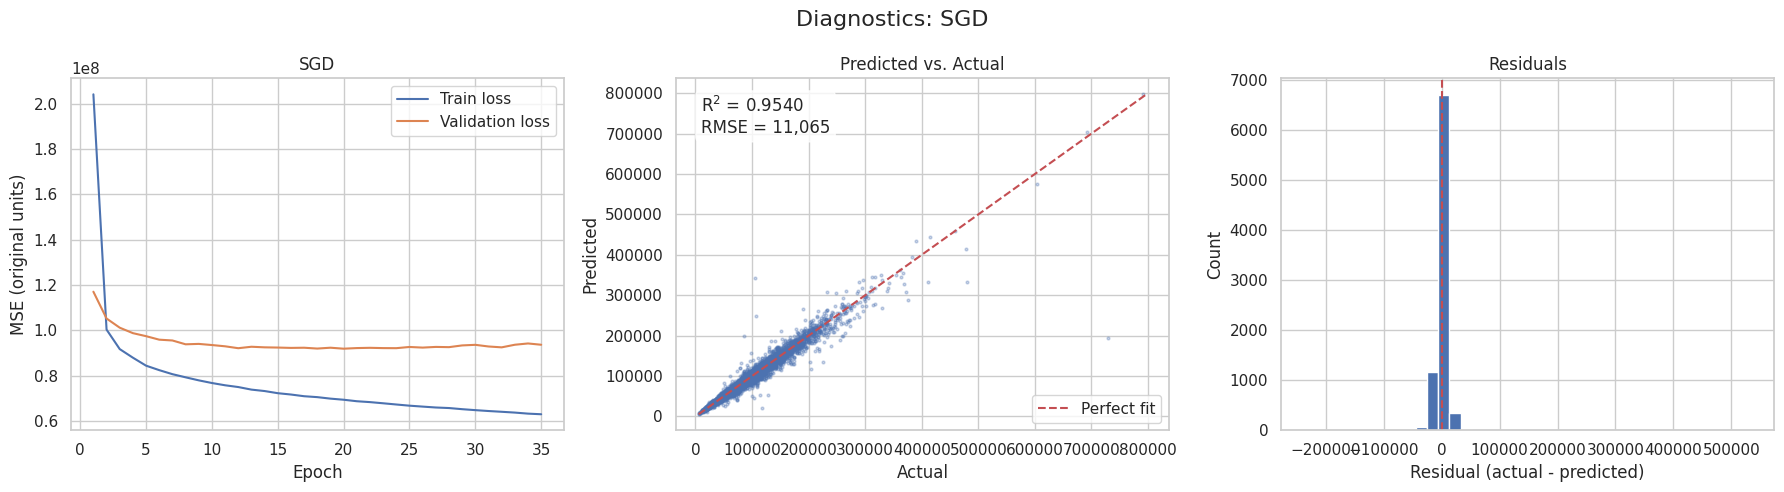

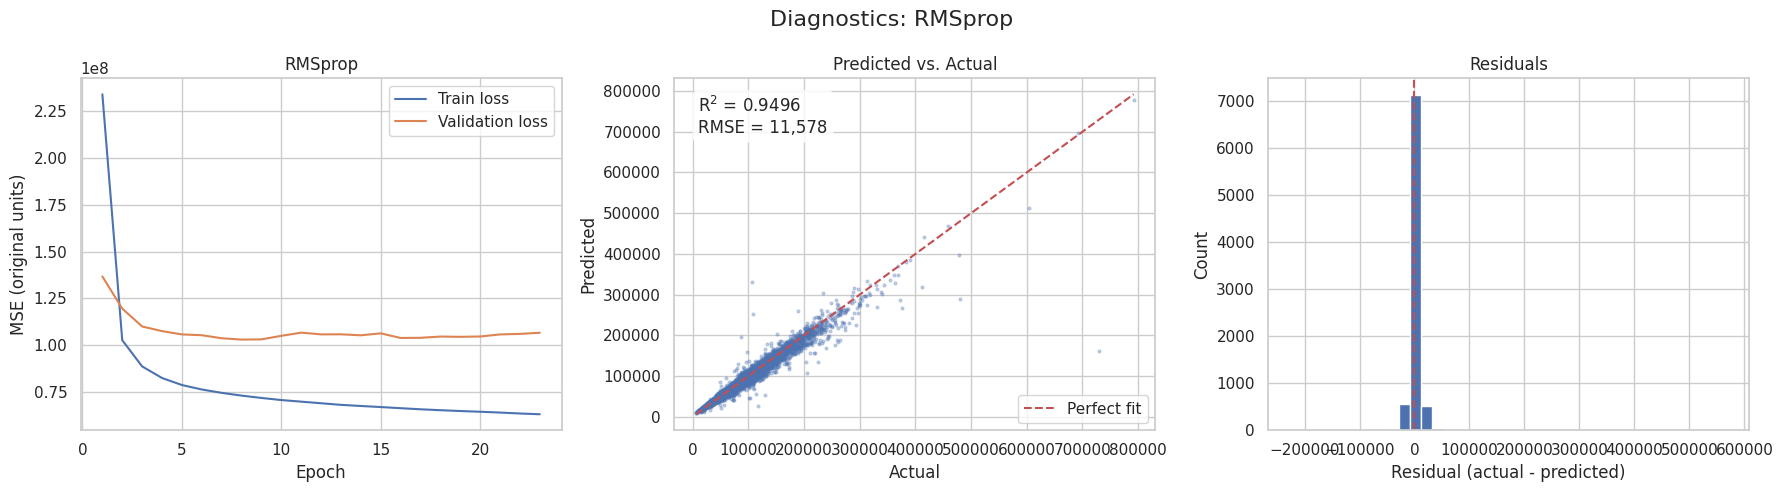

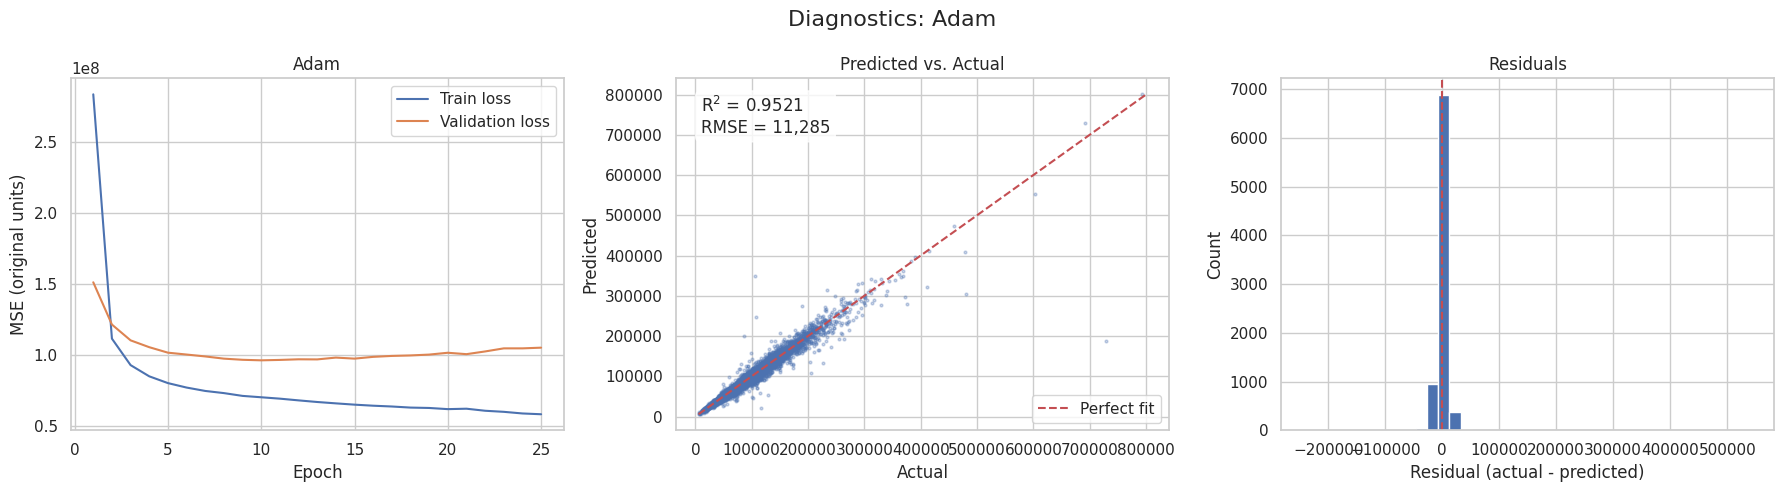

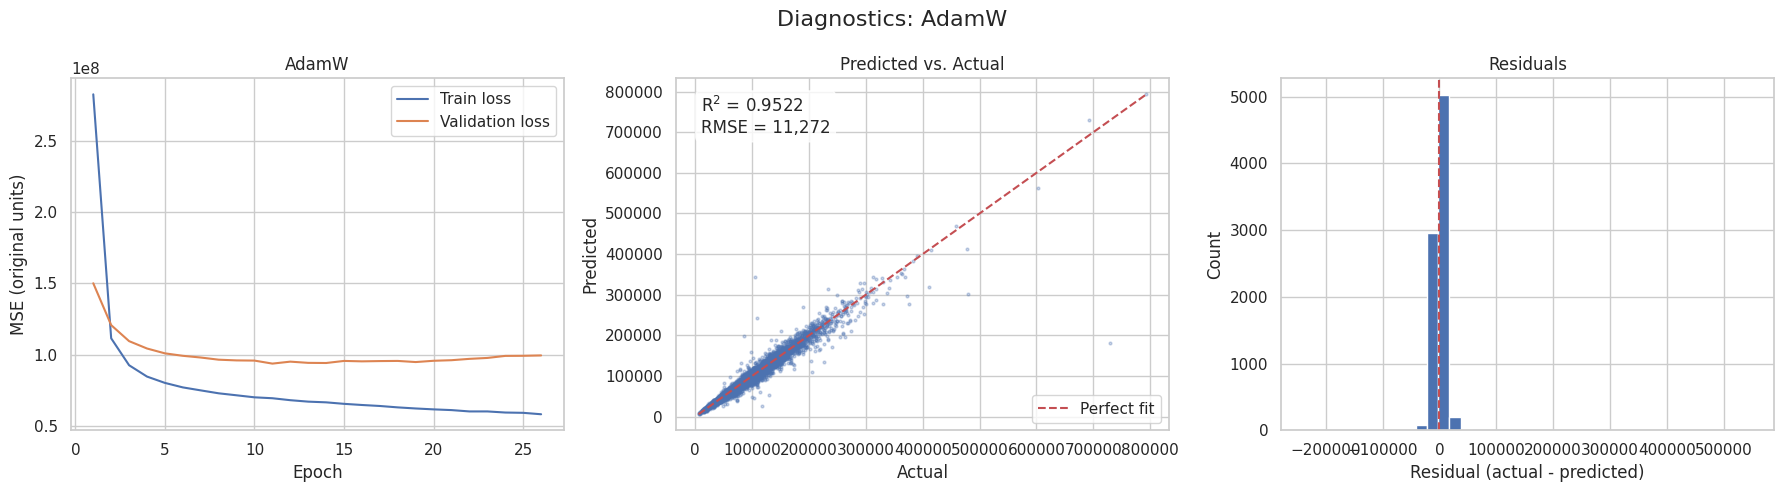

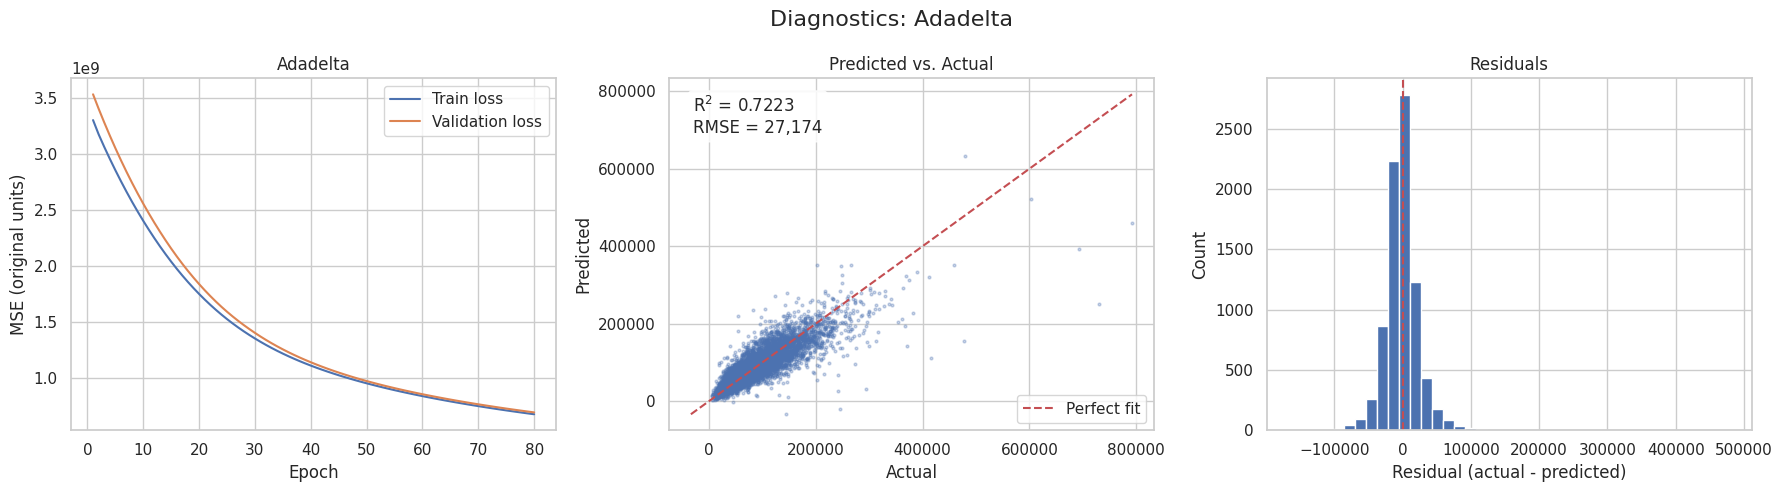

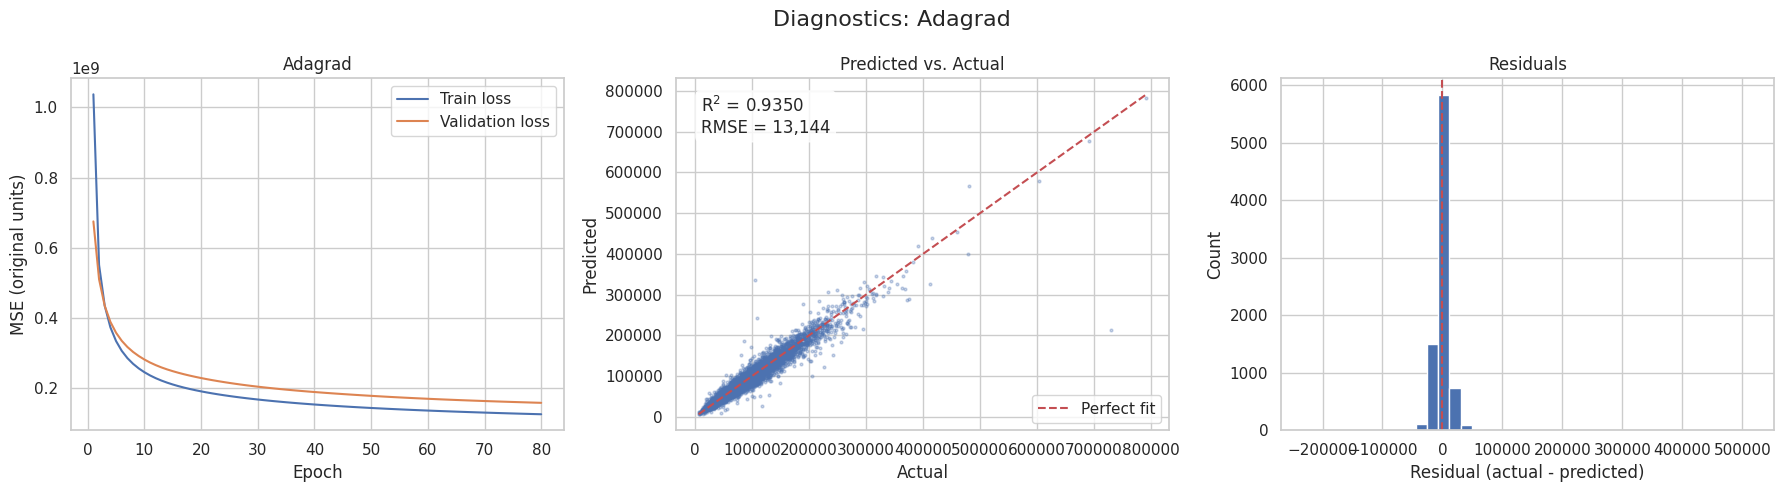

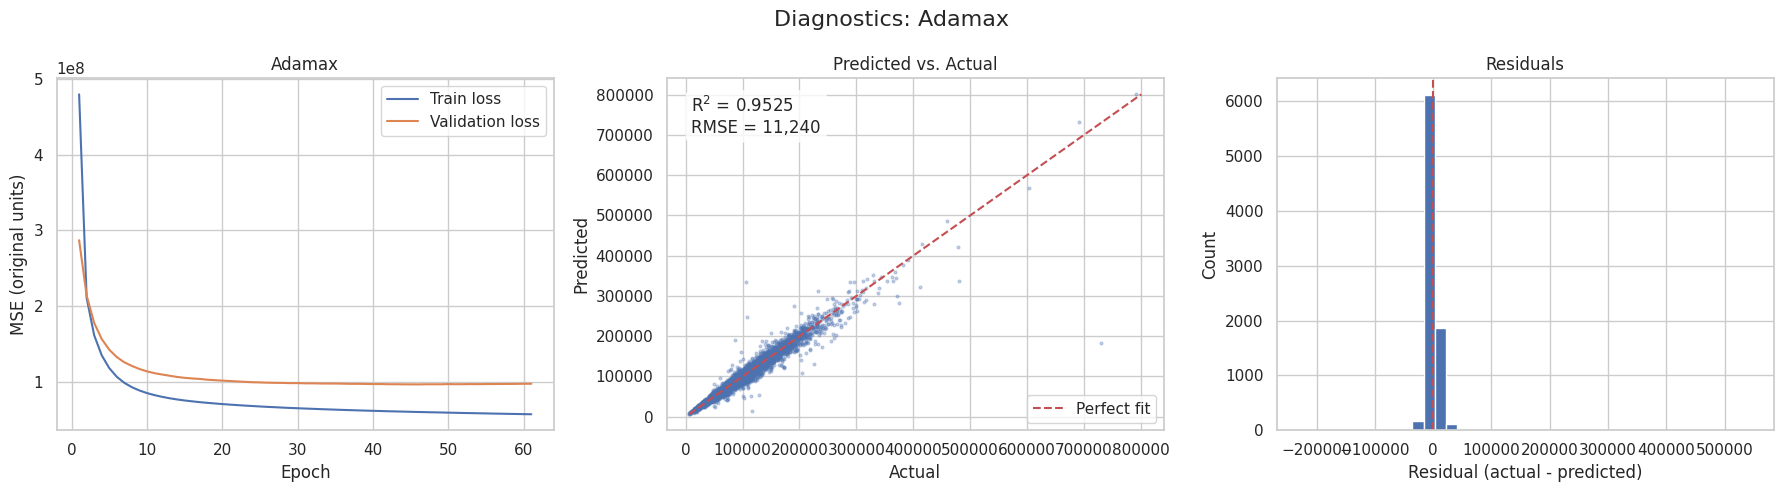

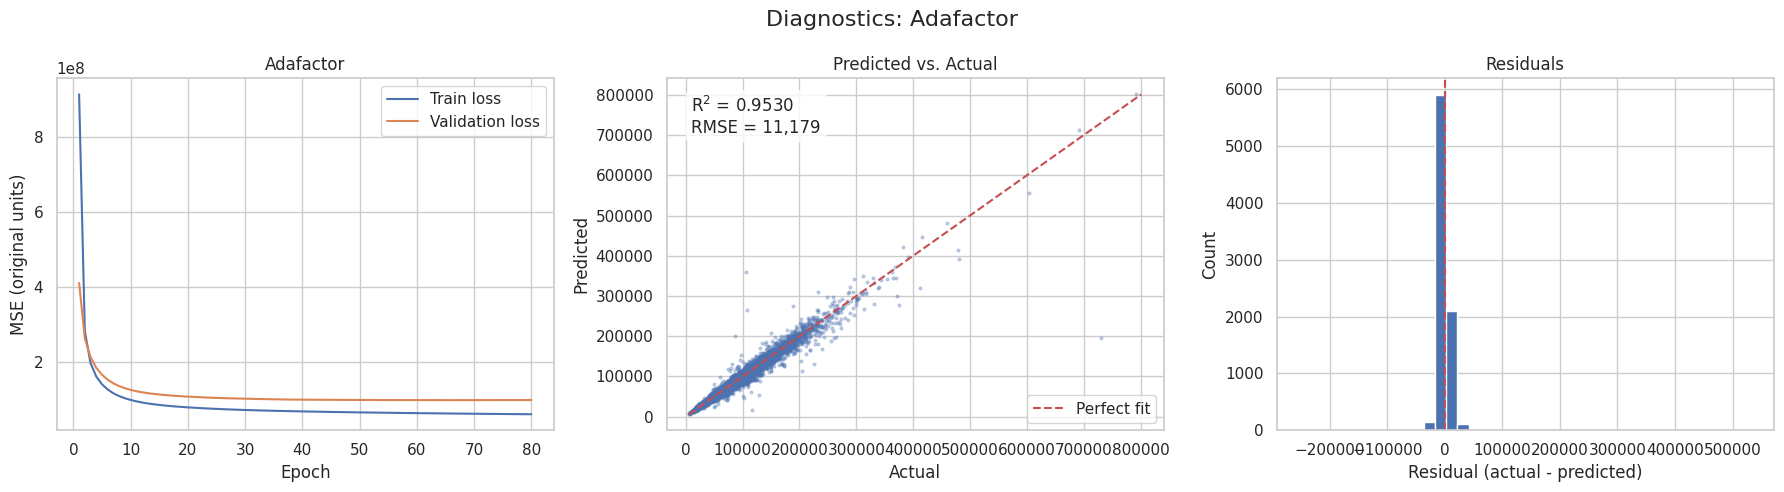

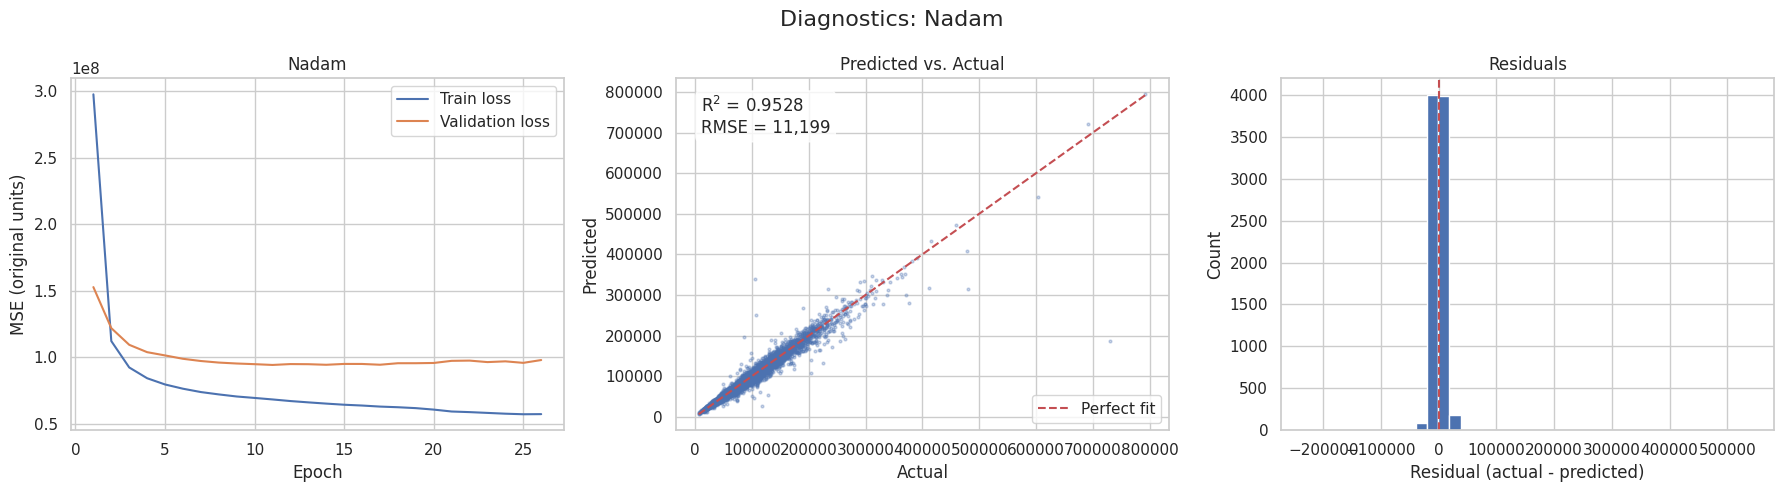

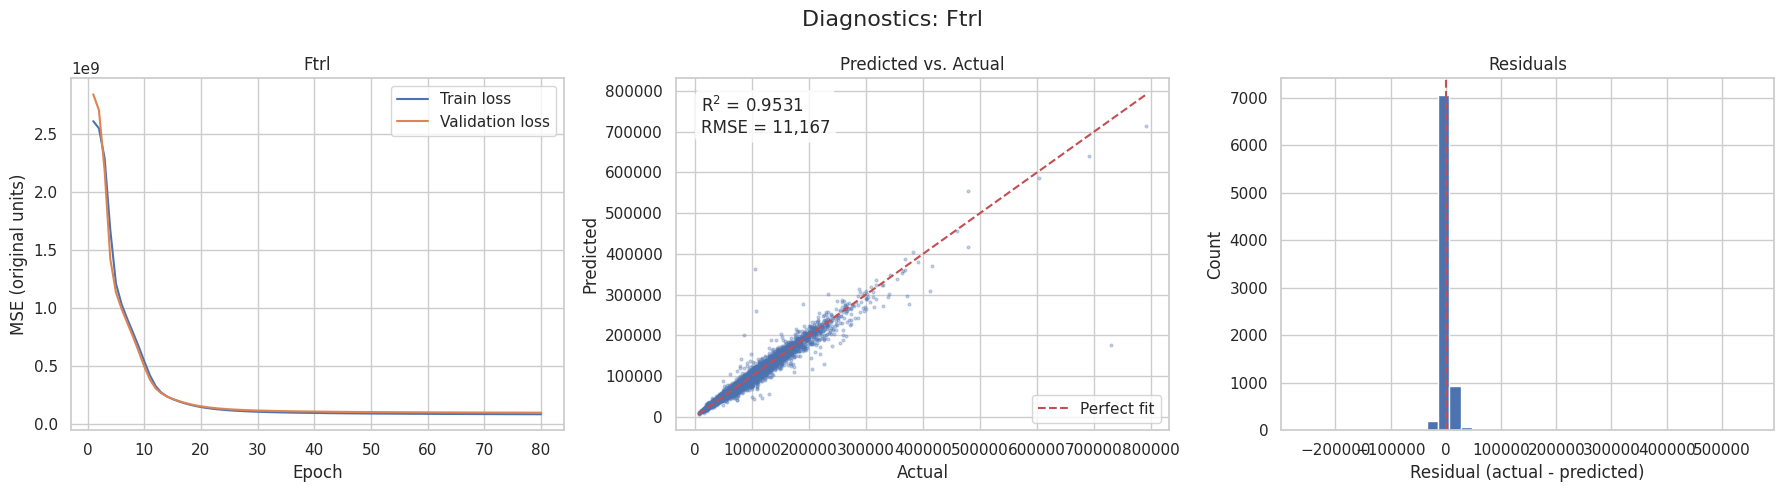

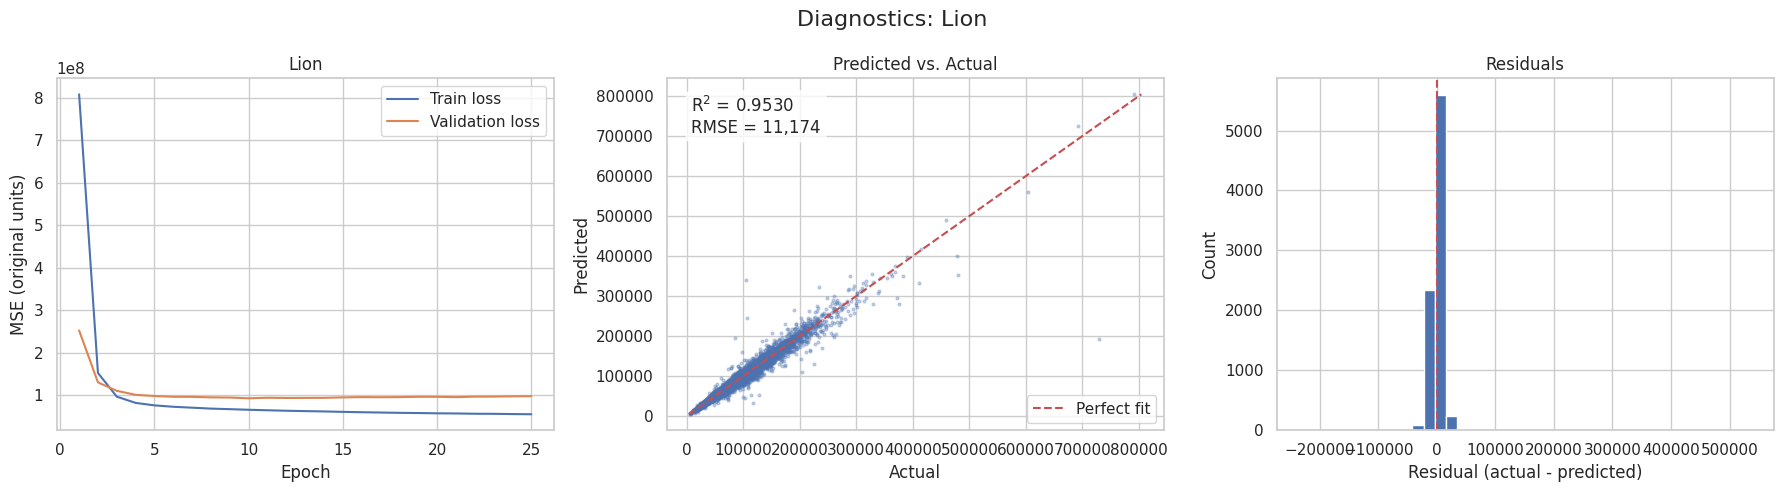

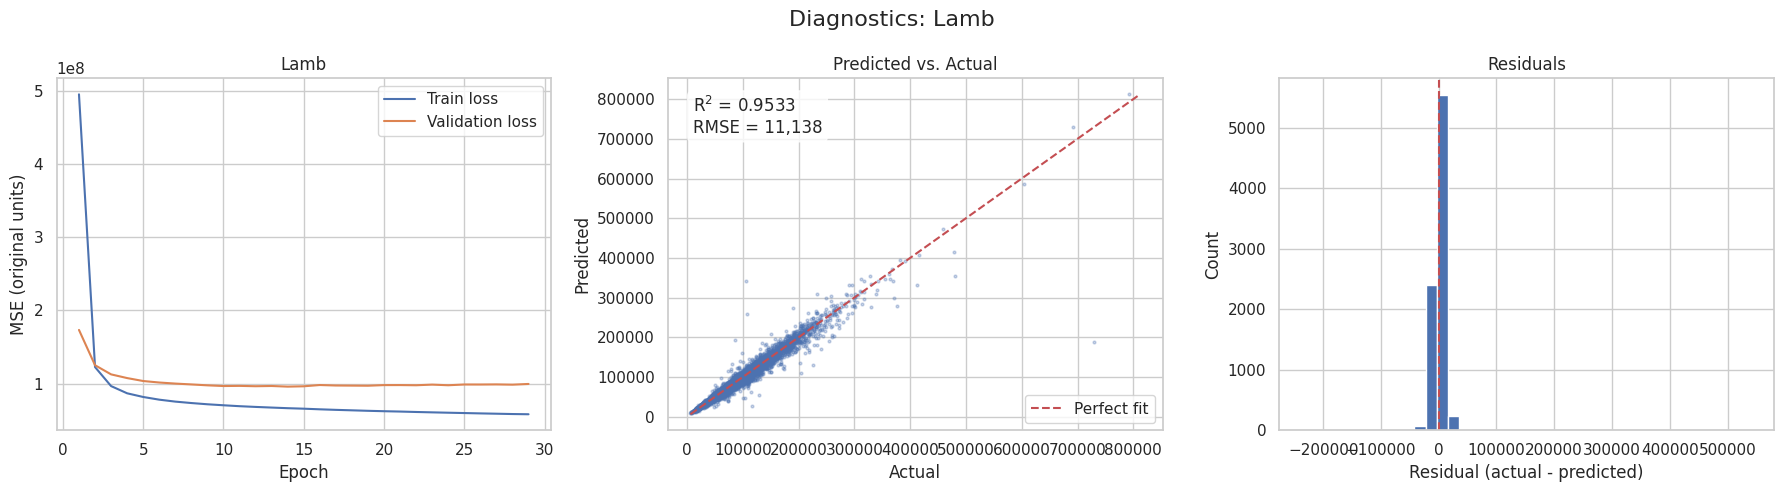

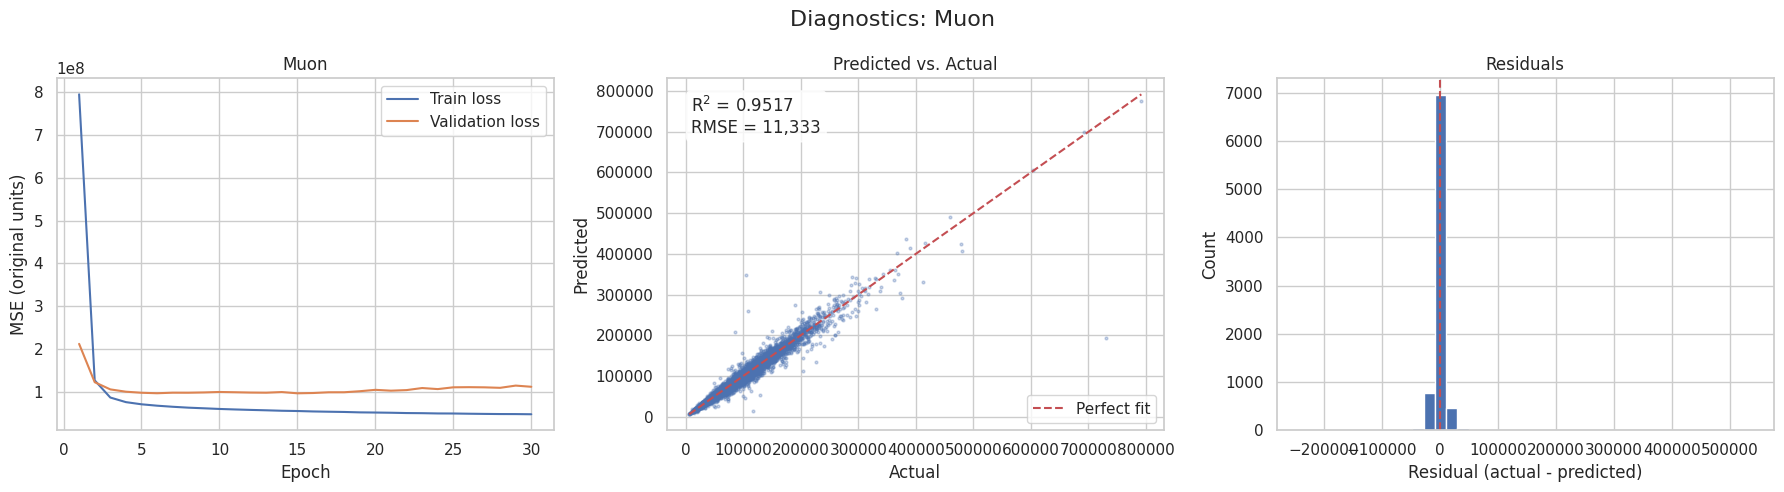

In [31]:
# 6.1 Per-Optimizer Diagnostic Plots
for name in OPT_NAMES:
    h = hist_orig[name]
    m = trained_models[name]
    mt = metrics[name]

    pred = scaler_y.inverse_transform(m.predict(X_test_s, verbose=0)).ravel()
    resid = y_test - pred

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # (a) loss curves
    ep = np.arange(1, len(h['loss']) + 1)
    axes[0].plot(ep, h['loss'], label='Train loss')
    axes[0].plot(ep, h['val_loss'], label='Validation loss')
    axes[0].set_title(name)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE (original units)')
    axes[0].legend()

    # (b) predicted vs actual
    axes[1].scatter(y_test, pred, s=4, alpha=0.3)
    lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
    axes[1].plot([lo, hi], [lo, hi], 'r--', label='Perfect fit')
    axes[1].set_xlabel('Actual'); axes[1].set_ylabel('Predicted')
    axes[1].set_title('Predicted vs. Actual')
    axes[1].text(0.05, 0.95, f"R$^2$ = {mt['R2']:.4f}\nRMSE = {mt['RMSE']:,.0f}",
                 transform=axes[1].transAxes, va='top',
                 bbox=dict(boxstyle='round', fc='white', alpha=0.8))
    axes[1].legend(loc='lower right')

    # (c) residual histogram
    axes[2].hist(resid, bins=40)
    axes[2].axvline(0, color='r', linestyle='--')
    axes[2].set_xlabel('Residual (actual - predicted)'); axes[2].set_ylabel('Count')
    axes[2].set_title('Residuals')

    fig.suptitle(f'Diagnostics: {name}', fontsize=16)
    plt.tight_layout()
    fig.savefig(f'fig_{name.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()

#6.2 Comparative Plots

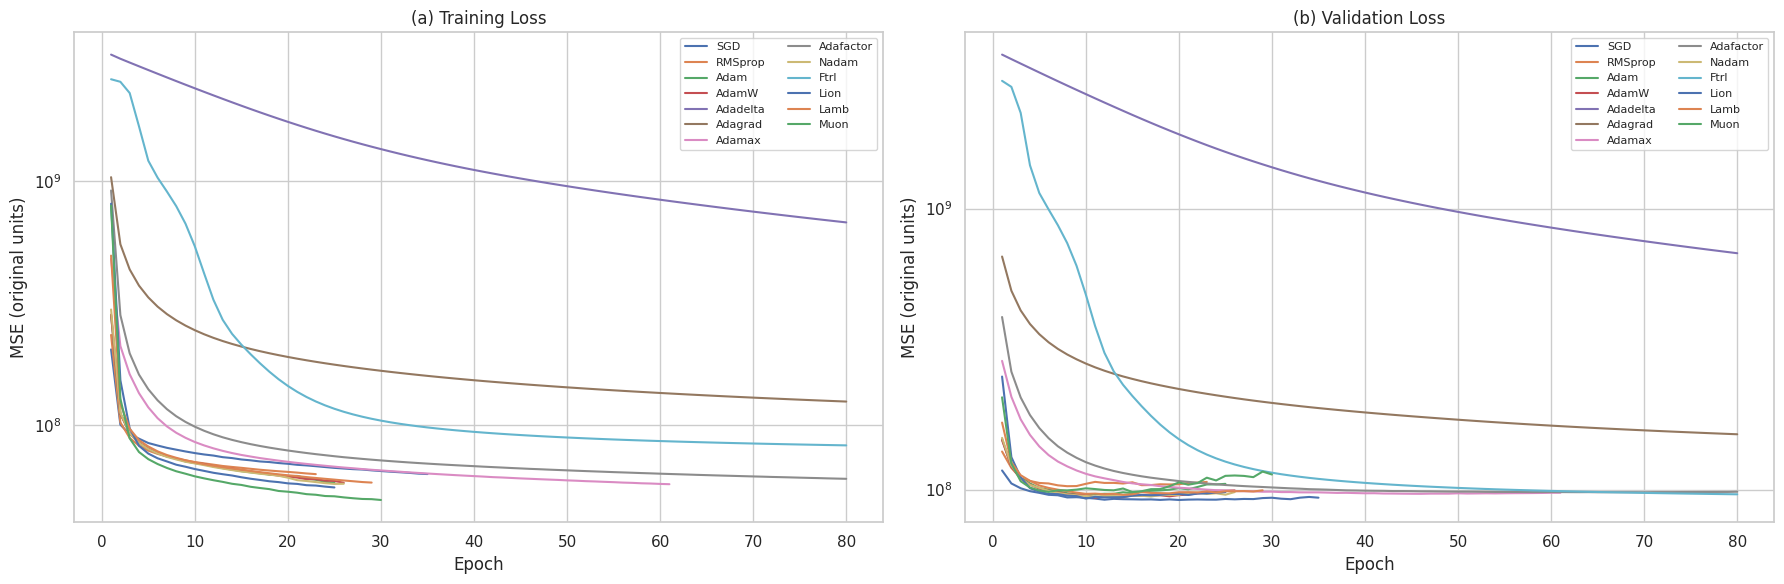

In [32]:
# 6.2 Comparative Plots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for name in OPT_NAMES:
    h = hist_orig[name]
    ep = np.arange(1, len(h['loss']) + 1)
    axes[0].plot(ep, h['loss'], label=name)
    axes[1].plot(ep, h['val_loss'], label=name)

axes[0].set_title('(a) Training Loss'); axes[1].set_title('(b) Validation Loss')
for a in axes:
    a.set_xlabel('Epoch'); a.set_ylabel('MSE (original units)')
    a.set_yscale('log')
    a.legend(ncol=2, fontsize=8)
plt.tight_layout()
fig.savefig('fig_all_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()

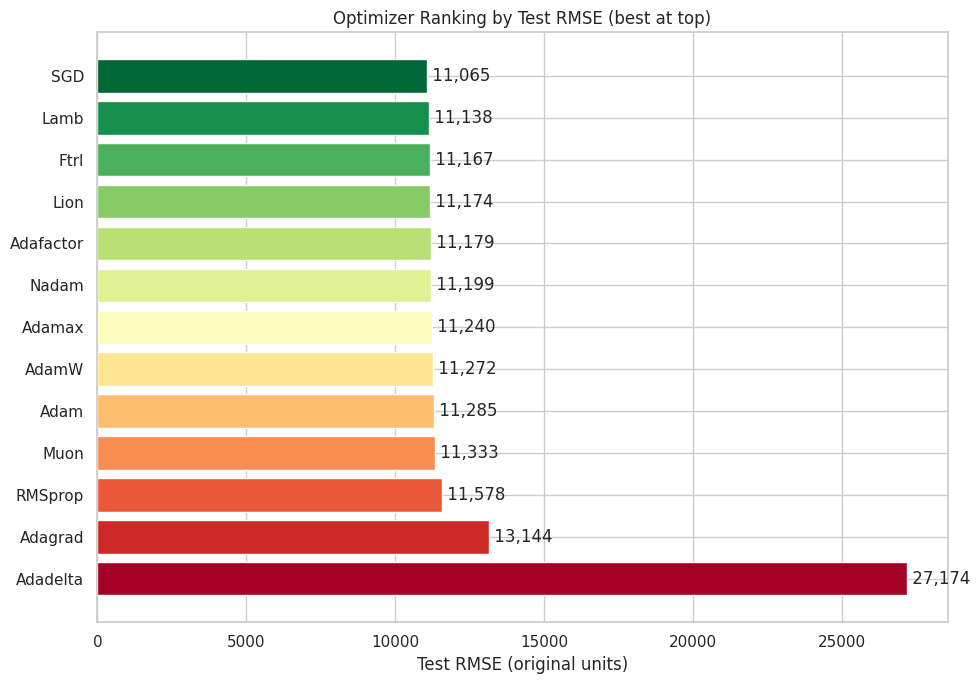

In [33]:
rank = results['RMSE'].sort_values()
colors = plt.cm.RdYlGn_r(np.linspace(0, 1, len(rank)))

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(rank.index[::-1], rank.values[::-1], color=colors[::-1])
for b, v in zip(bars, rank.values[::-1]):
    ax.text(v, b.get_y() + b.get_height() / 2, f' {v:,.0f}', va='center')
ax.set_xlabel('Test RMSE (original units)')
ax.set_title('Optimizer Ranking by Test RMSE (best at top)')
plt.tight_layout()
fig.savefig('fig_rmse_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [34]:
for name in OPT_NAMES:
    h = hist_orig[name]
    tr = np.array(h['loss'])
    va = np.array(h['val_loss'])
    print(f"{name:10s} train@5={tr[min(4,len(tr)-1)]:.2e}  train@10={tr[min(9,len(tr)-1)]:.2e}  "
          f"best_val_epoch={int(np.argmin(va))+1}  epochs_run={len(tr)}")

SGD        train@5=8.44e+07  train@10=7.67e+07  best_val_epoch=20  epochs_run=35
RMSprop    train@5=7.85e+07  train@10=7.05e+07  best_val_epoch=8  epochs_run=23
Adam       train@5=7.99e+07  train@10=6.99e+07  best_val_epoch=10  epochs_run=25
AdamW      train@5=8.00e+07  train@10=6.99e+07  best_val_epoch=11  epochs_run=26
Adadelta   train@5=2.85e+09  train@10=2.40e+09  best_val_epoch=80  epochs_run=80
Adagrad    train@5=3.34e+08  train@10=2.45e+08  best_val_epoch=80  epochs_run=80
Adamax     train@5=1.18e+08  train@10=8.52e+07  best_val_epoch=46  epochs_run=61
Adafactor  train@5=1.40e+08  train@10=9.84e+07  best_val_epoch=70  epochs_run=80
Nadam      train@5=7.97e+07  train@10=6.96e+07  best_val_epoch=11  epochs_run=26
Ftrl       train@5=1.21e+09  train@10=5.40e+08  best_val_epoch=80  epochs_run=80
Lion       train@5=7.64e+07  train@10=6.60e+07  best_val_epoch=10  epochs_run=25
Lamb       train@5=8.17e+07  train@10=7.03e+07  best_val_epoch=14  epochs_run=29
Muon       train@5=7.25e+07  

In [35]:
for name in ['SGD', 'Adam']:
    va = np.array(hist_orig[name]['val_loss'])
    print(name, 'epochs run:', len(va), 'best epoch:', int(np.argmin(va)) + 1)
    print('  val loss at epochs 1,5,10,15,20,25,30,35:',
          [f'{va[e-1]:.2e}' for e in [1,5,10,15,20,25,30,35] if e <= len(va)])

SGD epochs run: 35 best epoch: 20
  val loss at epochs 1,5,10,15,20,25,30,35: ['1.17e+08', '9.74e+07', '9.35e+07', '9.24e+07', '9.19e+07', '9.26e+07', '9.36e+07', '9.36e+07']
Adam epochs run: 25 best epoch: 10
  val loss at epochs 1,5,10,15,20,25,30,35: ['1.51e+08', '1.01e+08', '9.59e+07', '9.71e+07', '1.01e+08', '1.05e+08']


## 8. Convergence Analysis (Bonus)

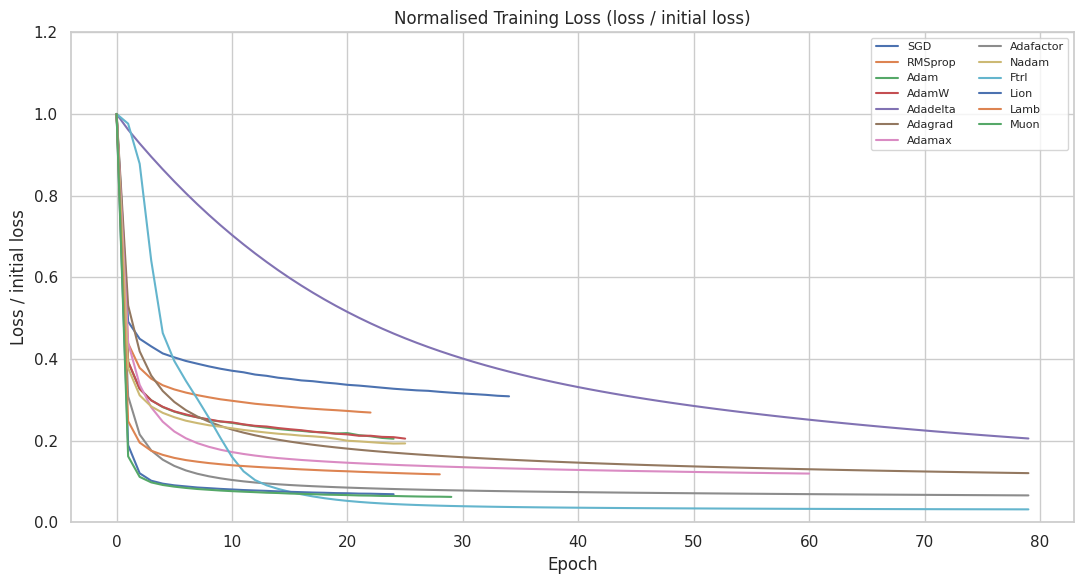

,loss at epoch 5 / initial
Muon,0.091306
Lion,0.094534
Adafactor,0.153212
Lamb,0.165027
Adamax,0.246269
Nadam,0.267922
Adam,0.282024
AdamW,0.282766
Adagrad,0.321505
RMSprop,0.335515


In [36]:
fig, ax = plt.subplots(figsize=(11, 6))
for name in OPT_NAMES:
    l = np.array(histories[name]['loss'])
    ax.plot(l / l[0], label=name)
ax.set_ylim(0, 1.2)
ax.set_title('Normalised Training Loss (loss / initial loss)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss / initial loss')
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
fig.savefig('fig_convergence_normalised.png', dpi=150, bbox_inches='tight')
plt.show()

early = {n: histories[n]['loss'][min(4, len(histories[n]['loss'])-1)] / histories[n]['loss'][0]
         for n in OPT_NAMES}
pd.Series(early, name='loss at epoch 5 / initial').sort_values()

In [37]:
nl = {n: np.array(histories[n]['loss']) / histories[n]['loss'][0] for n in histories}
pd.DataFrame({
    'upward epochs': {n: int((np.diff(v) > 0).sum()) for n, v in nl.items()},
    'smoothness after epoch 5': {n: round(float(np.std(np.diff(v)[5:])), 4) for n, v in nl.items()}
}).sort_values('smoothness after epoch 5')

,upward epochs,smoothness after epoch 5
Muon,0,0.0007
Lion,0,0.0007
Lamb,0,0.0011
RMSprop,0,0.0017
AdamW,1,0.0018
SGD,0,0.0018
Adafactor,0,0.0018
Nadam,1,0.0019
Adam,1,0.0020
Adamax,0,0.0030
